# 01 · EDA and speaker labels

**Project question:** Are superstars more self-focused than role players in NBA press conferences?

This notebook:
1. loads the scraped ASAP Sports transcripts (one row per answer),
2. labels every speaker as **player / coach / other** and every player-answer as **superstar** (All-Star *in that season*) or **non-superstar**,
3. adds text features (pronoun counts and rates, "you" in the reporter's question),
4. explores the data, and
5. saves `data/answers_labeled.csv` for the analysis notebook.

The comparisons here are **descriptive only**. They do not control for game result, points, round or question type; that is the job of the mixed-effects model in the next notebook.

In [1]:
import sys, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from label_speakers import label

FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 140, "display.max_columns", 30)

# Chart style: validated categorical slots 1-2, recessive axes and grid
STAR, OTHER = "#2a78d6", "#eb6834"          # superstar = blue, non-superstar = orange
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": "#b4b2a9", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False,
})

## 1. Load the scraped data

In [2]:
raw = pd.read_csv(ROOT / "data" / "asap_nba_answers.csv", dtype=str, keep_default_na=False)
print(f"{len(raw):,} answers from {raw.interview_id.nunique():,} press conferences, "
      f"{raw.year.min()}-{raw.year.max()}")
raw.head(3)

60,322 answers from 6,321 press conferences, 2004-2026


,interview_id,turn,year,date,event,round,game_info,session,score_line,listed_speakers,listed_team,speaker,is_coach_label,question,answer,n_words,url
0,29762,0,2004,"June 6, 2004",NBA FINALS: PISTONS v LAKERS,finals,"LOS ANGELES, CALIFORNIA: Game One",postgame_probable,,Larry Brown,,COACH LARRY BROWN,1,Three years ago you played the Lakers in the F...,"I was with Philly then. (Laughing). No, I thin...",145,https://www.asapsports.com/show_interview.php?...
1,29762,1,2004,"June 6, 2004",NBA FINALS: PISTONS v LAKERS,finals,"LOS ANGELES, CALIFORNIA: Game One",postgame_probable,,Larry Brown,,COACH LARRY BROWN,1,"I actually meant, do the Lakers look different...","No, Lakers. Oh. I apologize. (Laughter) wow. T...",139,https://www.asapsports.com/show_interview.php?...
2,29762,2,2004,"June 6, 2004",NBA FINALS: PISTONS v LAKERS,finals,"LOS ANGELES, CALIFORNIA: Game One",postgame_probable,,Larry Brown,,COACH LARRY BROWN,1,"Chauncey came into the league as a scorer, how...","Well, we would not be here if it wasn't for hi...",166,https://www.asapsports.com/show_interview.php?...


## 2. Label speakers

`scripts/label_speakers.py` does the labelling:

- **season**: the year the NBA season ends (a June 2024 Finals game and a Dec 2023 NBA Cup game are both season 2024). Playoff games always count in their calendar year, because the 2020 "bubble" playoffs ran into October.
- **person**: speaker labels are matched to the names in the transcript header, so variants such as "STEPH CURRY" and "STEPHEN CURRY" become one person.
- **role**:
  - `coach` if the person appears in Wikipedia's head-coach lists from their first coaching season on. Jason Kidd is therefore a player in 2011 and a coach in 2022.
  - `other` for moderators, commissioners, executives and award presenters.
  - `player` otherwise.
- **superstar** = 1 if the player was **selected as an All-Star that season**, from Wikipedia's *List of NBA All-Stars*. Selected-but-injured players count as selected.

In [3]:
df = label(raw)
df["role"].value_counts().rename("answers").to_frame()

,answers
role,
player,37856
coach,20969
other,1497


In [4]:
players = df[df.role == "player"].copy()
summary = (players.assign(group=players.superstar.map({1: "superstar", 0: "non-superstar"}))
           .groupby("group")
           .agg(answers=("answer", "size"), players=("person_key", "nunique"),
                words=("n_words", "sum"), median_words=("n_words", "median"),
                press_conferences=("interview_id", "nunique")))
print(f"Unique players: {players.person_key.nunique()}  "
      f"(ever a superstar in these data: {players.loc[players.superstar == 1, 'person_key'].nunique()})")
summary

Unique players: 438  (ever a superstar in these data: 77)


,answers,players,words,median_words,press_conferences
group,,,,,
non-superstar,19249,410,1358834,61.0,2503
superstar,18607,77,1448770,71.0,1841


A player can sit in **both** groups across seasons. For example, Draymond Green is a superstar in 2016–18 and a non-superstar in 2015 and 2019. Because the label follows the season, this is intended: it lets us compare the same person in star and non-star seasons later.

In [5]:
both = players.groupby("person_key").superstar.nunique()
print("Players who appear in both groups:", int((both == 2).sum()))
(players[players.person_key.isin(both[both == 2].index)]
   .groupby(["person", "superstar"]).size().unstack(fill_value=0)
   .rename(columns={0: "non-superstar answers", 1: "superstar answers"})
   .sort_values("superstar answers", ascending=False).head(10))

Players who appear in both groups: 49


superstar,non-superstar answers,superstar answers
person,,
Stephen Curry,31,1530
Draymond Green,423,764
Klay Thompson,231,653
Tim Duncan,137,514
Tony Parker,133,498
Jayson Tatum,22,371
Pau Gasol,83,315
Dwight Howard,95,310
Chris Paul,154,273


### Sanity check: who is in each group?

In [6]:
top = lambda g: (players[players.superstar == g].groupby("person").size()
                 .sort_values(ascending=False).head(15))
pd.DataFrame({"superstars (answers)": [f"{p} ({n})" for p, n in top(1).items()],
              "non-superstars (answers)": [f"{p} ({n})" for p, n in top(0).items()]})

,superstars (answers),non-superstars (answers)
0,LeBron James (2485),Draymond Green (423)
1,Stephen Curry (1530),Andre Iguodala (352)
2,Kobe Bryant (1044),Manu Ginobili (339)
3,Dwyane Wade (1014),J.R. Smith (312)
4,Kevin Durant (885),Jrue Holiday (270)
5,Draymond Green (764),Derek Fisher (265)
6,Klay Thompson (653),Tristan Thompson (261)
7,Tim Duncan (514),Lamar Odom (256)
8,Tony Parker (498),Danny Green (250)
9,Chris Bosh (440),Klay Thompson (231)


## 3. Text features

| Feature | Definition |
|---|---|
| `i_count` | *I, me, my, mine, myself, I'm, I've, I'll, I'd* in the answer |
| `we_count` | *we, us, our, ours, ourselves, we're, we've, we'll, we'd* in the answer |
| `i_rate`, `we_rate` | count per 1,000 words of the answer |
| `we_share` | we / (I + we): 0 means only "I", 1 means only "we" |
| `q_you_rate` | *you, your, yours, yourself, you're, you've, you'll, you'd* per 1,000 words of the **question** |

In [7]:
I_WORDS  = {"i", "me", "my", "mine", "myself", "i'm", "i've", "i'll", "i'd"}
WE_WORDS = {"we", "us", "our", "ours", "ourselves", "we're", "we've", "we'll", "we'd"}
YOU_WORDS = {"you", "your", "yours", "yourself", "yourselves", "you're", "you've", "you'll", "you'd"}

def tokens(s):
    return re.findall(r"[a-z']+", s.lower().replace("’", "'"))

def count(s, vocab):
    return sum(t in vocab for t in tokens(s))

df["i_count"] = df.answer.map(lambda s: count(s, I_WORDS))
df["we_count"] = df.answer.map(lambda s: count(s, WE_WORDS))
df["q_words"] = df.question.map(lambda s: len(tokens(s)))
df["q_you_count"] = df.question.map(lambda s: count(s, YOU_WORDS))
nz = df.n_words.replace(0, np.nan)
df["i_rate"] = 1000 * df.i_count / nz
df["we_rate"] = 1000 * df.we_count / nz
df["we_share"] = df.we_count / (df.i_count + df.we_count).replace(0, np.nan)
df["q_you_rate"] = 1000 * df.q_you_count / df.q_words.replace(0, np.nan)

players = df[df.role == "player"].copy()
players[["n_words", "i_count", "we_count", "i_rate", "we_rate", "we_share", "q_you_rate"]].describe().round(1)

,n_words,i_count,we_count,i_rate,we_rate,we_share,q_you_rate
count,37856.0,37856.0,37856.0,37856.0,37856.0,34521.0,37422.0
mean,74.2,3.1,2.9,45.9,38.5,0.5,78.8
std,53.1,3.9,3.5,56.9,42.8,0.4,54.9
min,1.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,38.0,0.0,0.0,0.0,0.0,0.0,43.5
50%,65.0,2.0,2.0,28.2,27.0,0.5,76.9
75%,100.0,4.0,5.0,67.2,63.8,0.8,111.1
max,947.0,95.0,38.0,1000.0,1000.0,1.0,1000.0


## 4. Exploring the data

### 4.1 Where the data come from

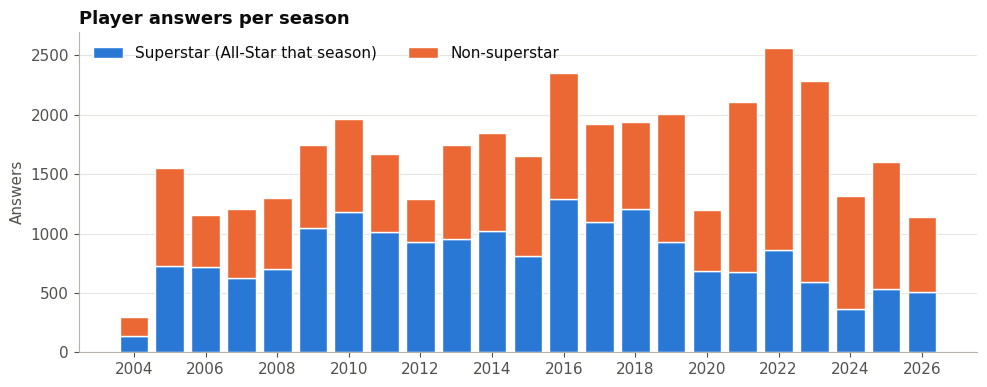

In [8]:
by_season = players.groupby(["season", "superstar"]).size().unstack(fill_value=0).reindex(columns=[1, 0])
fig, ax = plt.subplots(figsize=(10, 4))
x = by_season.index.astype(int)
ax.bar(x, by_season[1], color=STAR, width=0.8, label="Superstar (All-Star that season)",
       edgecolor="white", linewidth=1)
ax.bar(x, by_season[0], bottom=by_season[1], color=OTHER, width=0.8, label="Non-superstar",
       edgecolor="white", linewidth=1)
ax.set_title("Player answers per season")
ax.set_ylabel("Answers")
ax.set_xticks(x[::2])
ax.legend(loc="upper left", ncols=2)
fig.tight_layout(); fig.savefig(FIG / "answers_per_season.png", dpi=200); plt.show()

In [9]:
(players.groupby(["round", "superstar"]).size().unstack(fill_value=0)
   .rename(columns={0: "non-superstar", 1: "superstar"})
   .assign(total=lambda t: t.sum(axis=1)).sort_values("total", ascending=False))

superstar,non-superstar,superstar,total
round,,,
finals,10605,8912,19517
conference_finals,6806,7986,14792
first_round,875,703,1578
conference_semifinals,561,582,1143
nba_cup,262,402,664
play_in,104,0,104
regular_season_special,36,22,58


In [10]:
(players.groupby(["session", "superstar"]).size().unstack(fill_value=0)
   .rename(columns={0: "non-superstar", 1: "superstar"})
   .pipe(lambda t: (100 * t / t.sum()).round(1)).add_suffix(" %"))

superstar,non-superstar %,superstar %
session,,
postgame,20.5,18.1
postgame_probable,15.0,33.1
practice,61.5,47.6
pregame,0.1,0.0
unknown,2.9,1.1


### 4.2 How many answers per player?
A few stars contribute a lot. This is why the model needs a **random effect per player**, and why the charts below average **per player** rather than per answer.

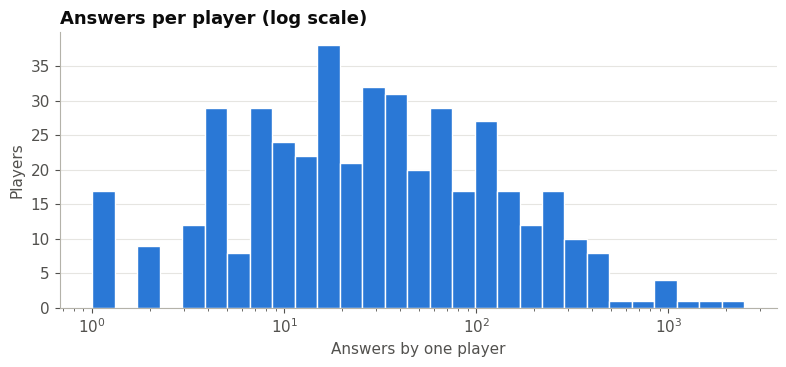

Median answers per player: 27; top 5 players account for 19.3% of player answers


In [11]:
per_player = players.groupby("person_key").size()
fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.logspace(0, np.log10(per_player.max() + 1), 30)
ax.hist(per_player, bins=bins, color=STAR, edgecolor="white", linewidth=1)
ax.set_xscale("log")
ax.set_title("Answers per player (log scale)")
ax.set_xlabel("Answers by one player"); ax.set_ylabel("Players")
fig.tight_layout(); fig.savefig(FIG / "answers_per_player.png", dpi=200); plt.show()
top5 = per_player.sort_values(ascending=False).head(5)
print(f"Median answers per player: {per_player.median():.0f}; "
      f"top 5 players account for {100 * top5.sum() / per_player.sum():.1f}% of player answers")

### 4.3 Pronoun use by group (descriptive, unadjusted)
Each dot is one **player in one group**, pooled across their answers (a player in both groups gives two dots). Only player-groups with at least 1,000 words are shown, so the rates are stable.

superstar
non-superstar player-groups    241
superstar player-groups         69
dtype: int64


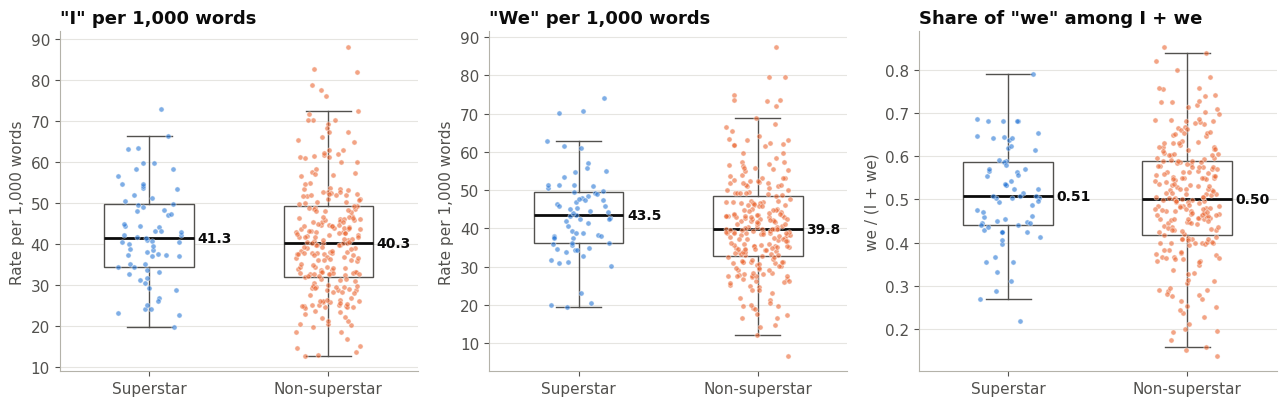

,i_rate,we_rate,we_share,q_you_rate
superstar,,,,
non-superstar (median player),40.26,39.82,0.50,75.24
superstar (median player),41.32,43.48,0.51,78.43


In [12]:
pg = (players.groupby(["person", "superstar"])
      .agg(words=("n_words", "sum"), i=("i_count", "sum"), we=("we_count", "sum"),
           q_words=("q_words", "sum"), q_you=("q_you_count", "sum"), answers=("answer", "size"))
      .reset_index())
pg = pg[pg.words >= 1000].copy()
pg["i_rate"] = 1000 * pg.i / pg.words
pg["we_rate"] = 1000 * pg.we / pg.words
pg["q_you_rate"] = 1000 * pg.q_you / pg.q_words.replace(0, np.nan)
pg["we_share"] = pg.we / (pg.i + pg.we)
print(pg.groupby("superstar").size().rename({0: "non-superstar player-groups", 1: "superstar player-groups"}))

def group_panel(ax, col, title, ylabel):
    rng = np.random.default_rng(4054)
    for pos, (g, colr) in enumerate([(1, STAR), (0, OTHER)]):
        v = pg.loc[pg.superstar == g, col].dropna()
        ax.boxplot(v, positions=[pos], widths=0.5, showfliers=False, patch_artist=True,
                   boxprops=dict(facecolor="white", edgecolor=INK2), medianprops=dict(color=INK, linewidth=2),
                   whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
        ax.scatter(pos + rng.uniform(-0.18, 0.18, len(v)), v, s=14, color=colr, alpha=0.6,
                   edgecolor="white", linewidth=0.5, zorder=3)
        ax.text(pos + 0.27, v.median(), f"{v.median():.2f}" if v.median() < 1 else f"{v.median():.1f}",
                va="center", ha="left", color=INK, fontsize=10, fontweight="bold")
    ax.set_xticks([0, 1], ["Superstar", "Non-superstar"])
    ax.set_title(title); ax.set_ylabel(ylabel)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
group_panel(axes[0], "i_rate", '"I" per 1,000 words', "Rate per 1,000 words")
group_panel(axes[1], "we_rate", '"We" per 1,000 words', "Rate per 1,000 words")
group_panel(axes[2], "we_share", 'Share of "we" among I + we', "we / (I + we)")
fig.tight_layout(); fig.savefig(FIG / "pronouns_by_group.png", dpi=200); plt.show()

pg.groupby("superstar")[["i_rate", "we_rate", "we_share", "q_you_rate"]].median().round(2) \
  .rename(index={0: "non-superstar (median player)", 1: "superstar (median player)"})

### 4.4 Are superstars asked different questions?
If reporters address stars with more "you" questions, stars may say "I" more simply because of the question. This is the question confound from the project plan.

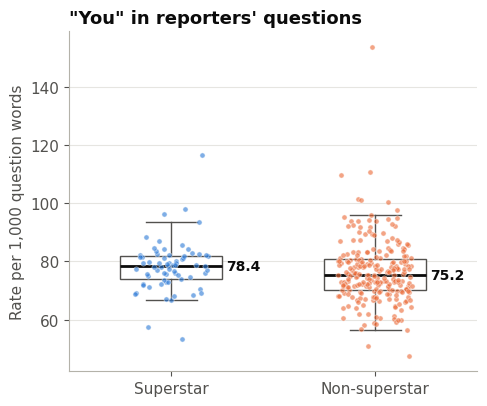

In [13]:
fig, ax = plt.subplots(figsize=(5, 4.2))
group_panel(ax, "q_you_rate", '"You" in reporters\' questions', "Rate per 1,000 question words")
fig.tight_layout(); fig.savefig(FIG / "question_you_by_group.png", dpi=200); plt.show()

### 4.5 Answer length

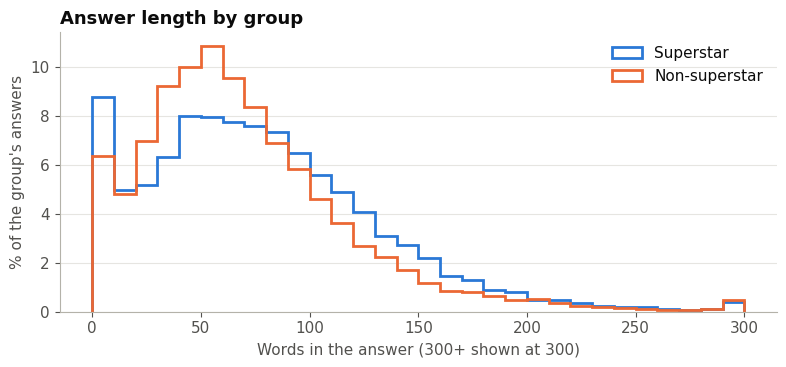

,count,mean,std,min,25%,50%,75%,max
superstar,,,,,,,,
non-superstar,19249.0,71.0,51.0,1.0,37.0,61.0,93.0,947.0
superstar,18607.0,78.0,55.0,1.0,39.0,71.0,108.0,645.0


In [14]:
fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.arange(0, 310, 10)
for g, colr, name in [(1, STAR, "Superstar"), (0, OTHER, "Non-superstar")]:
    v = players.loc[players.superstar == g, "n_words"].clip(upper=300)
    ax.hist(v, bins=bins, histtype="step", linewidth=2, color=colr, label=name,
            weights=np.full(len(v), 100 / len(v)))
ax.set_title("Answer length by group")
ax.set_xlabel("Words in the answer (300+ shown at 300)"); ax.set_ylabel("% of the group's answers")
ax.legend()
fig.tight_layout(); fig.savefig(FIG / "answer_length_by_group.png", dpi=200); plt.show()
players.groupby("superstar").n_words.describe().round(0).rename(index={0: "non-superstar", 1: "superstar"})

## 5. Save the labelled data

In [15]:
cols = ["interview_id", "turn", "season", "date", "event", "round", "session", "postgame", "game_info",
        "score_line", "listed_team", "speaker", "person", "person_key", "role", "superstar",
        "career_allstar_selections", "question", "answer", "n_words", "i_count", "we_count",
        "i_rate", "we_rate", "we_share", "q_words", "q_you_count", "q_you_rate", "url"]
out = ROOT / "data" / "answers_labeled.csv"
df[cols].to_csv(out, index=False)
print(f"Saved {len(df):,} rows ({(df.role == 'player').sum():,} player answers) to {out.relative_to(ROOT)}")

Saved 60,322 rows (37,856 player answers) to data\answers_labeled.csv


## 6. Caveats before modelling

- **Unadjusted.** Section 4 compares raw rates. Differences may come from game result, points scored, playoff round, session type or question wording rather than status.
- **Missing controls.** Win/loss (from `score_line`) and points scored (box scores) are still to be added.
- **Label errors.** Speaker attribution and the coach and executive lists were checked by hand on samples, not row by row. Rare speakers, such as one-off award-ceremony guests, may still be mislabelled.
- **Superstar = All-Star that season.** Players just below All-Star level (e.g. strong starters) count as non-superstars. An alternative split (bench players only) is worth testing as a robustness check.